# HC18 Fetal Head Circumference — Exploratory Data Analysis


## [official HC18 / Zenodo dataset page](https://zenodo.org/records/1322001).




## 1. Upload the dataset files
Upload the training images ZIP archive and the CSV containing pixel spacing and head circumference measurements.

In [ ]:
from pathlib import Path

dataset_dir = Path("dataset")

ZIP_FILE = str(dataset_dir / "training_set.zip")
CSV_FILE = str(dataset_dir / "training_set_pixel_size_and_HC.csv")

if not Path(ZIP_FILE).is_file():
    raise FileNotFoundError(f"Training archive not found: {ZIP_FILE}")

if not Path(CSV_FILE).is_file():
    raise FileNotFoundError(f"Measurement CSV not found: {CSV_FILE}")

print("Training archive:", ZIP_FILE)
print("Measurement CSV:", CSV_FILE)

## 2. Extract files and inspect dataset structure

In [4]:
import os, zipfile, glob, re
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

DATA_DIR = os.path.join(os.path.dirname(os.path.abspath(CSV_FILE)), "hc18_data")
os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_FILE, "r") as archive:
    archive.extractall(DATA_DIR)

all_files = [
    path for path in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True)
    if os.path.isfile(path)
]
image_files = [
    path for path in all_files
    if path.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"))
]

df = pd.read_csv(CSV_FILE)

print(f"Files extracted: {len(all_files)}")
print(f"Image files found: {len(image_files)}")
print(f"CSV rows: {len(df)}")
print("\nCSV columns:")
print(df.columns.tolist())
print("\nFirst five CSV rows:")
display(df.head())
print("\nExample image paths:")
for path in image_files[:15]:
    print(os.path.relpath(path, DATA_DIR))


Files extracted: 1999
Image files found: 1998
CSV rows: 999

CSV columns:
['filename', 'pixel size', 'head circumference (mm)']

First five CSV rows:


,filename,pixel size,head circumference (mm)
0,1_HC.png,0.069136,44.30
1,2_HC.png,0.089659,56.81
2,3_HC.png,0.062033,68.75
3,4_HC.png,0.091291,69.00
4,5_HC.png,0.061240,59.81



Example image paths:
training_set\100_2HC.png
training_set\100_2HC_Annotation.png
training_set\101_HC.png
training_set\101_HC_Annotation.png
training_set\102_2HC.png
training_set\102_2HC_Annotation.png
training_set\103_HC.png
training_set\103_HC_Annotation.png
training_set\104_HC.png
training_set\104_HC_Annotation.png
training_set\105_HC.png
training_set\105_HC_Annotation.png
training_set\106_HC.png
training_set\106_HC_Annotation.png
training_set\107_HC.png


## 3. Check image dimensions and file quality

This calculates image width/height, image mode, unreadable images, and duplicate file hashes. Exact duplicate detection is based on file bytes; it does not detect visually similar images.

In [5]:
import hashlib
from collections import Counter

dimensions = []
modes = Counter()
unreadable = []
hash_to_paths = {}

for path in image_files:
    try:
        with Image.open(path) as im:
            dimensions.append((path, im.width, im.height))
            modes[im.mode] += 1
        with open(path, "rb") as f:
            digest = hashlib.md5(f.read()).hexdigest()
        hash_to_paths.setdefault(digest, []).append(path)
    except Exception as exc:
        unreadable.append((path, str(exc)))

dimension_df = pd.DataFrame(dimensions, columns=["path", "width", "height"])
print("Image modes:", dict(modes))
print("Unreadable images:", len(unreadable))
print("Exact duplicate groups:", sum(len(v) > 1 for v in hash_to_paths.values()))

if not dimension_df.empty:
    print("\nDimension counts:")
    display(
        dimension_df.groupby(["width", "height"]).size()
        .reset_index(name="number_of_images")
        .sort_values("number_of_images", ascending=False)
    )

if unreadable:
    print("\nUnreadable file examples:")
    print(unreadable[:5])


Image modes: {'L': 1998}
Unreadable images: 0
Exact duplicate groups: 3

Dimension counts:


,width,height,number_of_images
19,800,540,1950
20,800,542,10
2,780,544,2
1,780,539,2
0,738,541,2
4,783,541,2
3,782,542,2
5,783,543,2
6,786,542,2
9,789,545,2


## 4. Inspect the measurement CSV and calculate numerical statistics

The code below looks for columns whose names suggest head circumference or pixel spacing. Review the printed column names and detected candidates. If a field is not detected, set its exact column name manually in the configuration cell.

In [6]:
print("Column names and data types:")
display(pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "missing_values": [int(df[c].isna().sum()) for c in df.columns],
    "unique_values": [int(df[c].nunique(dropna=True)) for c in df.columns]
}))

def find_columns(patterns):
    found = []
    for col in df.columns:
        name = str(col).lower().replace("_", " ").replace("-", " ")
        if any(re.search(pattern, name) for pattern in patterns):
            found.append(col)
    return found

hc_candidates = find_columns([r"\bhc\b", r"circumference", r"head.*measure"])
spacing_candidates = find_columns([r"pixel.*size", r"pixel.*spacing", r"spacing", r"resolution"])

print("Possible head-circumference columns:", hc_candidates)
print("Possible pixel-spacing columns:", spacing_candidates)


Column names and data types:


,column,dtype,missing_values,unique_values
0,filename,object,0,999
1,pixel size,float64,0,993
2,head circumference (mm),float64,0,904


Possible head-circumference columns: ['head circumference (mm)']
Possible pixel-spacing columns: ['pixel size']


In [7]:
# If automatic detection did not find the right columns, enter their exact names here.
# Leave as None to use the first detected candidate.
HC_COLUMN = hc_candidates[0] if hc_candidates else None
PIXEL_SPACING_COLUMNS = spacing_candidates

print("Selected HC column:", HC_COLUMN)
print("Possible spacing columns:", PIXEL_SPACING_COLUMNS)

if HC_COLUMN is not None:
    hc_values = pd.to_numeric(df[HC_COLUMN], errors="coerce").dropna()
    if len(hc_values):
        print("\nHead circumference statistics (units depend on the CSV documentation):")
        display(hc_values.describe().rename("value").to_frame())
    else:
        print("The selected HC column contains no numeric values; inspect the CSV and set HC_COLUMN manually.")
else:
    print("No HC column detected automatically. Inspect df.head() and set HC_COLUMN to the correct column name.")

for col in PIXEL_SPACING_COLUMNS:
    numeric = pd.to_numeric(df[col], errors="coerce").dropna()
    if len(numeric):
        print(f"\nNumeric statistics for spacing-related column: {col}")
        display(numeric.describe().rename("value").to_frame())


Selected HC column: head circumference (mm)
Possible spacing columns: ['pixel size']

Head circumference statistics (units depend on the CSV documentation):


,value
count,999.000000
mean,174.383093
std,65.282061
min,44.300000
25%,153.600000
50%,174.060000
75%,189.825000
max,346.400000



Numeric statistics for spacing-related column: pixel size


,value
count,999.000000
mean,0.139846
std,0.053005
min,0.049415
25%,0.108801
50%,0.128357
75%,0.157678
max,0.393280


## 5. Plot the head-circumference distribution

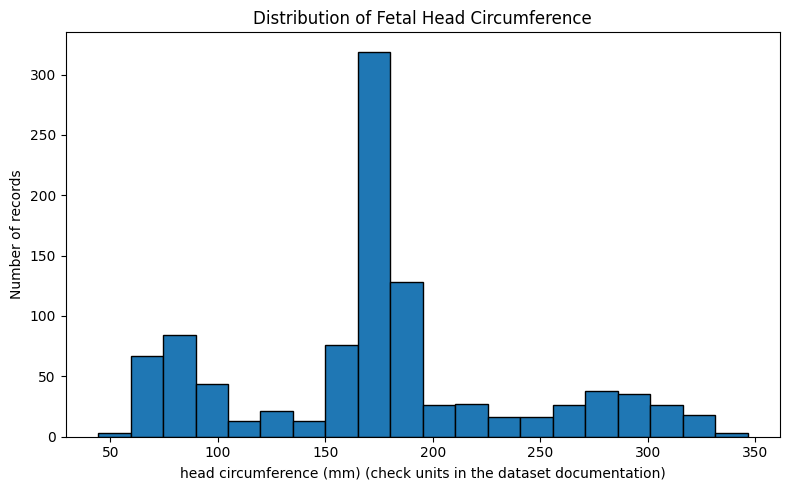

Valid numeric measurements: 999
Mean: 174.383
Median: 174.060
Standard deviation: 65.282
Minimum: 44.300
Maximum: 346.400


In [8]:
if HC_COLUMN is not None:
    hc_values = pd.to_numeric(df[HC_COLUMN], errors="coerce").dropna()
    if len(hc_values):
        plt.figure(figsize=(8, 5))
        plt.hist(hc_values, bins=20, edgecolor="black")
        plt.xlabel(f"{HC_COLUMN} (check units in the dataset documentation)")
        plt.ylabel("Number of records")
        plt.title("Distribution of Fetal Head Circumference")
        plt.tight_layout()
        plt.show()

        print(f"Valid numeric measurements: {len(hc_values)}")
        print(f"Mean: {hc_values.mean():.3f}")
        print(f"Median: {hc_values.median():.3f}")
        print(f"Standard deviation: {hc_values.std():.3f}")
        print(f"Minimum: {hc_values.min():.3f}")
        print(f"Maximum: {hc_values.max():.3f}")
    else:
        print("No numeric measurements available to plot.")
else:
    print("Set HC_COLUMN in Section 4 before plotting.")



Column: head circumference (mm)
Lower bound: 99.2625
Upper bound: 244.1625
Number of outliers: 336
Percentage of outliers: 33.63%
Outlier values:


,filename,head circumference (mm)
0,1_HC.png,44.30
1,2_HC.png,56.81
2,3_HC.png,68.75
3,4_HC.png,69.00
4,5_HC.png,59.81
...,...,...
994,995_HC.png,329.26
995,996_HC.png,330.90
996,997_HC.png,331.70
997,998_HC.png,316.48


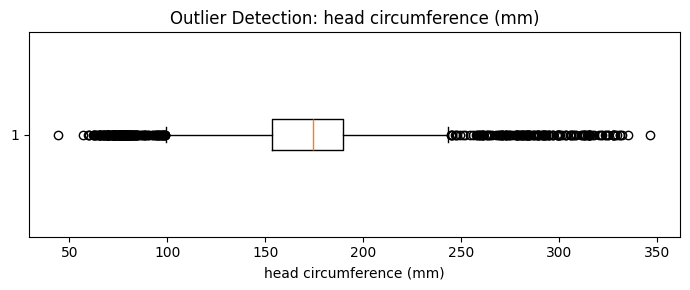


Column: pixel size
Lower bound: 0.0355
Upper bound: 0.2310
Number of outliers: 77
Percentage of outliers: 7.71%
Outlier values:


,filename,pixel size
293,294_HC.png,0.235922
498,499_2HC.png,0.235595
604,605_HC.png,0.239246
747,748_HC.png,0.238967
752,753_HC.png,0.235891
...,...,...
992,993_HC.png,0.279484
993,994_HC.png,0.235731
994,995_HC.png,0.296851
997,998_HC.png,0.281090


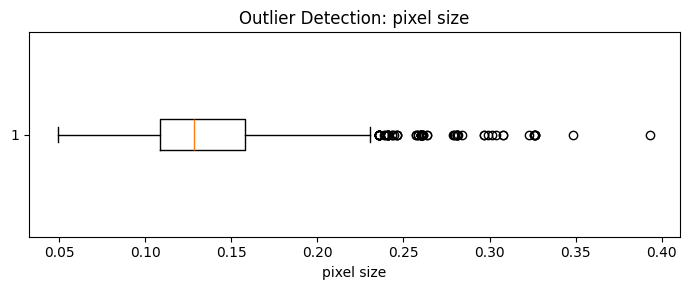

In [14]:

# Outlier Detection using the IQR method

columns_to_check = [
    "head circumference (mm)",
    "pixel size"
]

for col in columns_to_check:
    values = pd.to_numeric(df[col], errors="coerce").dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[(values < lower_bound) | (values > upper_bound)]

    print(f"\nColumn: {col}")
    print(f"Lower bound: {lower_bound:.4f}")
    print(f"Upper bound: {upper_bound:.4f}")
    print(f"Number of outliers: {len(outliers)}")
    print(f"Percentage of outliers: {len(outliers) / len(values) * 100:.2f}%")

    if not outliers.empty:
        print("Outlier values:")
        display(df.loc[outliers.index, ["filename", col]])

    # Visualize using a boxplot
    plt.figure(figsize=(7, 3))
    plt.boxplot(values, vert=False)
    plt.xlabel(col)
    plt.title(f"Outlier Detection: {col}")
    plt.tight_layout()
    plt.show()


## 6. Visualize representative ultrasound images

This displays up to five images from the downloaded archive. The filenames are shown so you can identify them. These are actual samples from the uploaded dataset, not examples fetched from the internet.

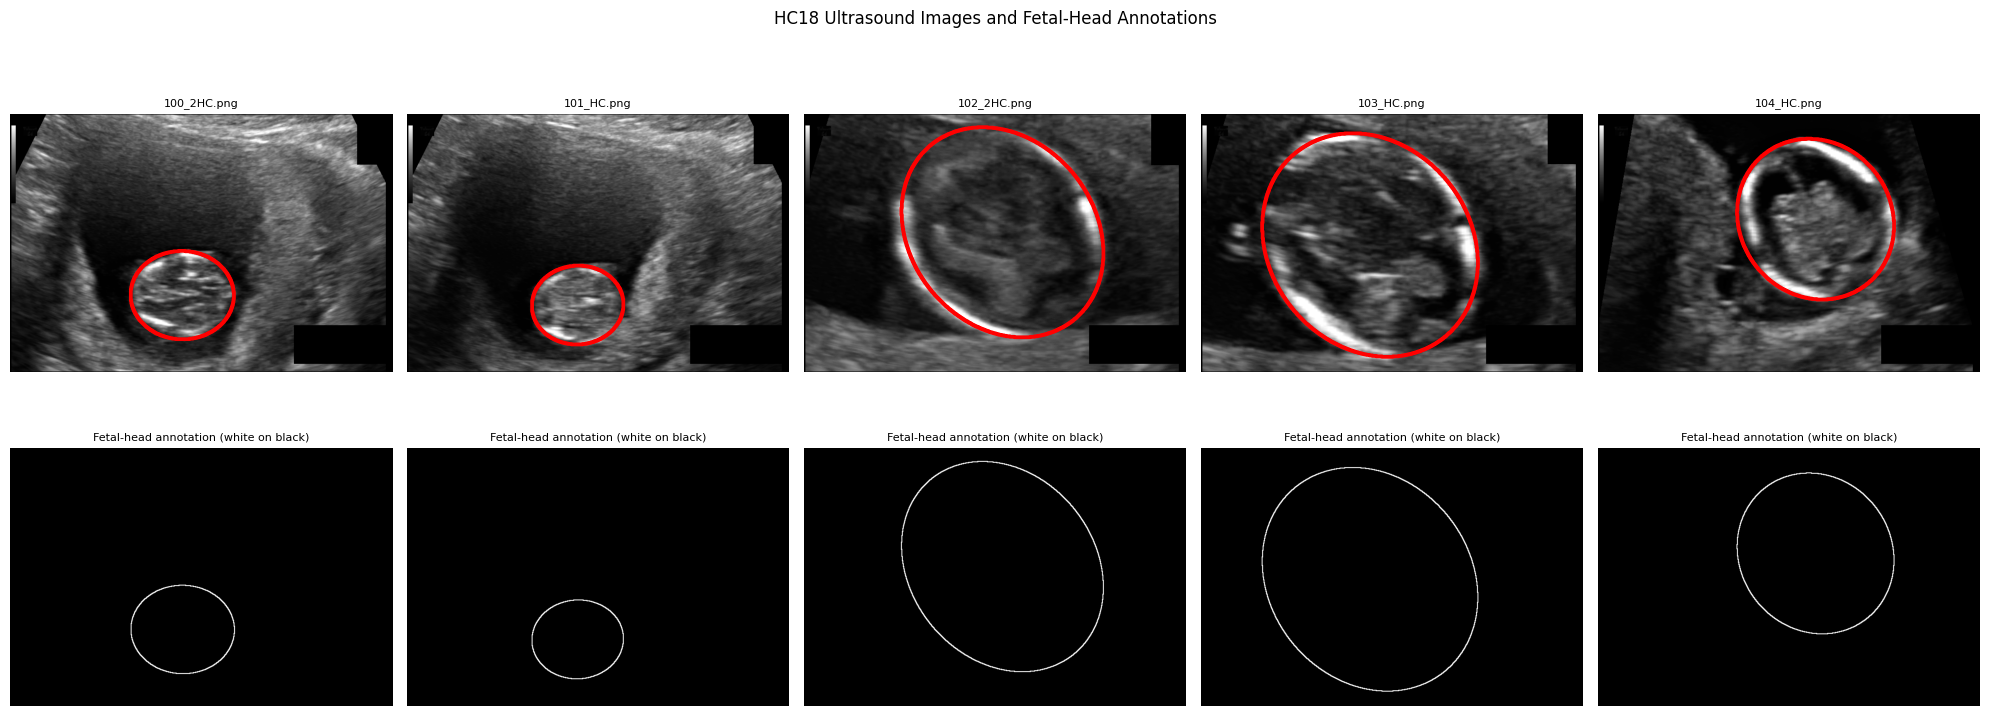

In [16]:
ultrasound_files = [
    path for path in image_files
    if "_annotation" not in os.path.basename(path).lower()
]

if not ultrasound_files:
    print("No ultrasound images found. Check that the correct training archive was uploaded.")
else:
    sample_paths = ultrasound_files[:min(5, len(ultrasound_files))]
    fig, axes = plt.subplots(2, len(sample_paths), figsize=(4 * len(sample_paths), 8), squeeze=False)

    for column, path in enumerate(sample_paths):
        annotation_path = os.path.splitext(path)[0] + "_Annotation.png"
        if not os.path.isfile(annotation_path):
            print(f"Annotation not found for {os.path.basename(path)}")
            continue

        with Image.open(path) as ultrasound:
            ultrasound_array = np.asarray(ultrasound.convert("L"))
        with Image.open(annotation_path) as annotation:
            mask = np.asarray(annotation.convert("L")) > 0

        axes[0, column].imshow(ultrasound_array, cmap="gray")
        axes[0, column].contour(mask, levels=[0.5], colors="red", linewidths=2)
        axes[0, column].set_title(os.path.basename(path), fontsize=8)
        axes[0, column].set_ylabel("Ultrasound + contour", fontsize=8)

        axes[1, column].imshow(mask, cmap="gray", vmin=0, vmax=1)
        axes[1, column].set_title("Fetal-head annotation (white on black)", fontsize=8)
        axes[1, column].set_ylabel("Annotation", fontsize=8)

        axes[0, column].axis("off")
        axes[1, column].axis("off")

    plt.suptitle("HC18 Ultrasound Images and Fetal-Head Annotations")
    plt.tight_layout()
    plt.show()


## 7. Locate and visualize annotation files

HC18 archives can organize image and annotation files differently. This cell lists filenames that look like annotations or masks. Review the output before assuming a file is a mask; some annotations may be stored as XML, CSV, or another format.

Potential annotation files found: 999
training_set\100_2HC_Annotation.png
training_set\101_HC_Annotation.png
training_set\102_2HC_Annotation.png
training_set\103_HC_Annotation.png
training_set\104_HC_Annotation.png
training_set\105_HC_Annotation.png
training_set\106_HC_Annotation.png
training_set\107_HC_Annotation.png
training_set\108_2HC_Annotation.png
training_set\109_HC_Annotation.png
training_set\10_2HC_Annotation.png
training_set\110_HC_Annotation.png
training_set\111_HC_Annotation.png
training_set\112_HC_Annotation.png
training_set\113_HC_Annotation.png
training_set\114_2HC_Annotation.png
training_set\115_HC_Annotation.png
training_set\116_HC_Annotation.png
training_set\117_HC_Annotation.png
training_set\118_HC_Annotation.png
training_set\119_HC_Annotation.png
training_set\11_2HC_Annotation.png
training_set\120_HC_Annotation.png
training_set\121_HC_Annotation.png
training_set\122_2HC_Annotation.png
training_set\123_HC_Annotation.png
training_set\124_2HC_Annotation.png
training_se

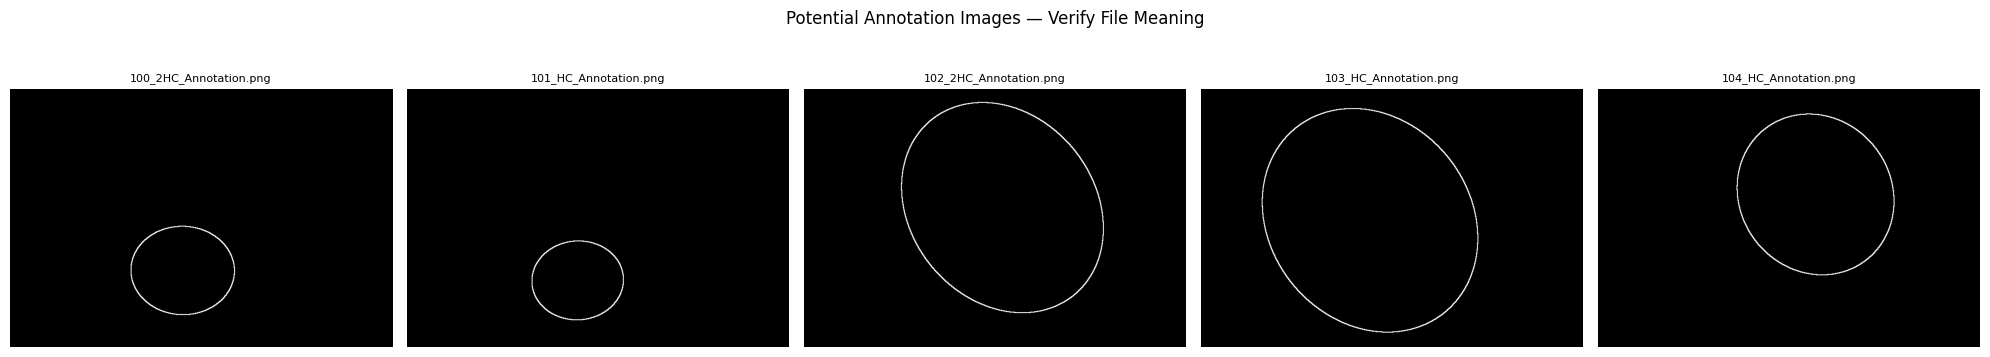

In [10]:
annotation_terms = ("annotation", "mask", "groundtruth", "ground_truth", "contour", "label")
annotation_files = [
    path for path in all_files
    if any(term in os.path.basename(path).lower() for term in annotation_terms)
    or os.path.splitext(path)[1].lower() in (".xml", ".json")
]

print(f"Potential annotation files found: {len(annotation_files)}")
for path in annotation_files[:40]:
    print(os.path.relpath(path, DATA_DIR))

# Display only likely raster masks/annotations. Verify each file before using it as ground truth.
raster_annotations = [
    p for p in annotation_files
    if p.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"))
]

if raster_annotations:
    paths = raster_annotations[:min(5, len(raster_annotations))]
    fig, axes = plt.subplots(1, len(paths), figsize=(4 * len(paths), 4))
    if len(paths) == 1:
        axes = [axes]
    for ax, path in zip(axes, paths):
        with Image.open(path) as im:
            ax.imshow(im, cmap="gray")
        ax.set_title(os.path.basename(path), fontsize=8)
        ax.axis("off")
    plt.suptitle("Potential Annotation Images — Verify File Meaning")
    plt.tight_layout()
    plt.show()
else:
    print(
        "\nNo raster annotations detected by filename. "
        "Inspect the official archive structure and CSV columns above. "
        "If annotations are in a separate archive or represented by contour coordinates, "
        "download/inspect that file and adapt the visualization accordingly."
    )


## 8. Check annotation availability and possible class imbalance

HC18 is a **segmentation and measurement** dataset, not a standard disease-classification dataset. There are no healthy/diseased classes to balance. Report measurement-distribution statistics instead. The following is a preliminary check of whether CSV rows contain missing values; it does not prove that every image has a matching annotation.

In [11]:
print("CSV records:", len(df))
print("Rows with any missing field:", int(df.isna().any(axis=1).sum()))
print("Rows with no missing fields:", int((~df.isna().any(axis=1)).sum()))

# Basic filename matching check, if a filename-like CSV column exists.
filename_candidates = [
    c for c in df.columns
    if any(word in str(c).lower() for word in ["filename", "file_name", "image", "image_id"])
]
print("Possible filename columns:", filename_candidates)

if filename_candidates:
    col = filename_candidates[0]
    known_basenames = {os.path.basename(p).lower() for p in image_files}
    csv_names = df[col].dropna().astype(str)
    matched = sum(os.path.basename(name).lower() in known_basenames for name in csv_names)
    print(f"Rows whose filename basename matches an extracted image: {matched}/{len(csv_names)}")
else:
    print("No filename column detected automatically; verify matching using the actual CSV schema.")


CSV records: 999
Rows with any missing field: 0
Rows with no missing fields: 999
Possible filename columns: ['filename']
Rows whose filename basename matches an extracted image: 999/999


## 9. Export tables for the report

This saves the CSV schema summary and image-dimension counts so you can download them and use the calculated values in your report.

In [13]:
schema_summary = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "missing_values": [int(df[c].isna().sum()) for c in df.columns],
    "unique_values": [int(df[c].nunique(dropna=True)) for c in df.columns]
})

output_dir = os.path.dirname(os.path.abspath(CSV_FILE))

schema_path = os.path.join(output_dir, "hc18_csv_schema_summary.csv")
schema_summary.to_csv(schema_path, index=False)

if not dimension_df.empty:
    dimension_summary = (
        dimension_df.groupby(["width", "height"])
        .size()
        .reset_index(name="number_of_images")
    )

    dimension_path = os.path.join(
        output_dir, "hc18_image_dimensions.csv"
    )
    dimension_summary.to_csv(dimension_path, index=False)

print(f"Saved: {schema_path}")

if not dimension_df.empty:
    print(f"Saved: {dimension_path}")

print("Report files are saved in the dataset folder.")

Saved: c:\Users\DELL\Desktop\university\Fall 2026\Pattern Recognition\Tasks\task 3\dataset\hc18_csv_schema_summary.csv
Saved: c:\Users\DELL\Desktop\university\Fall 2026\Pattern Recognition\Tasks\task 3\dataset\hc18_image_dimensions.csv
Report files are saved in the dataset folder.
